# Markov Chains

Author: Moreno Marzolla

Date: 2026-11-13

---

## Discrete-Time Markov Chains (DTMC)

### Mathematical definition

A Discrete-Time Markov Chain (DTMC) is a set of stochastic variables $\{X(n), n \in \mathbb{N}\}$ over the state space $K=\{0, \ldots, k-1\}$. $X(n) \in K$ is the system state at step $n$; we assume that there are $k$ different states. The Markov property requires that the state $X(n+1)$ at time $n+1$ depends only on the state $X(n)$ at time $n$. This dependency is defined by a _transition matrix_
$\mathbf{P} = [p_{ij}]$, $i, j \in \{0, \ldots, k-1\}$, where $p_{ij}$ is the probability that the next state is $j$ assuming that the current state is $i$: $p_{ij} = P( X(n+1) = j\ |\ X(n) = i\}$. Note that $p_{ij}$ must be independent of $n$.

The stochastic matrix $\mathbf{P}$ must satisfy the following properties:

1. All entries of $\mathbf{P}$ must be probabilities: $0 \leq p_{ij} \leq 1$ for all $i, j \in K$;
2. The sum of the outgoing probabilities $p_{ij}$ from any state $i$ is one. Therefore, if the system is currently in state $i$, it must go to another valid state (possibly including itself) with probability 1: $\sum_{j \in K} p_{ij} = 1$ for every $i \in K$.

Given the initial state occupancy probabilities $\boldsymbol{\pi}(0)$, $\boldsymbol{\pi}(n)$ can be computed as:

$$
\boldsymbol{\pi}(n) = \boldsymbol{\pi}(0) \mathbf{P}^n
$$

where $\boldsymbol{\pi}(n)$ is an array of length $k$. Under certain conditions, there exists a steady-state ocupancy probability vector $\mathbf{\pi}$ that is independent from $\boldsymbol{\pi}(0)$, and can be computed as the solution of the set of linear equations:

$$
\left\{
\begin{align}
\boldsymbol{\pi P} &= \boldsymbol{\pi}\\
\boldsymbol{\pi} \mathbf{1}^T &= \mathbf{1}
\end{align}
\right.
$$

where $\mathbf{1}^T$ is a column array of length $k$ containing all 1. This is a system of $k+1$ equations with $k$ unknowns; however, it can be reduced to a system of $k$ equations by dropping any one of the first $k$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from scipy.integrate import quad_vec, solve_ivp

EPSILON = 10 * np.finfo(float).eps

def dtmc(P, *args):
    """
    dtmc(P)
    dtmc(P,n,p0)

    This is a (mostly automatic) translation of the dtmc()
    function from the Octave queueing package
    ( https://www.moreno.marzolla.name/software/queueing/ ).
    
    Returns the state occupancy probabilities after n transitions
    of a DTMC with matrix P and initial state p0. If invoked
    with a single argument P, returns the steady-state
    probability distribution.
    """
    P = np.asarray(P, dtype=float) # ensure P is of the proper type
    assert P.shape[0] == P.shape[1], "Matrix P must be square"
    k = P.shape[0] # number of states
    if len(args) == 0: # stationary analysis
        # Solve xA = 0 where A = P - I
        A = P - np.identity(k)
        b = np.zeros(k)
        # overwrite the last row of A with the normalization condition x 1 = 1
        A[:,k-1] = 1
        b[k-1] = 1
        if np.linalg.matrix_rank(A) < k:
            raise ValueError("P is reducible; no steady-state probability exists")
        # We need to solve xA = b; unfortunately, np.linalg.solve(A, b)
        # solves Ax = b. Hence, we transpose A to get the intended result
        return np.linalg.solve(A.T, b) # solve Ax = b
    else: # transient analysis
        n = args[0]
        p0 = args[1]
        return np.matmul(p0, np.linalg.matrix_power(P, n))

### Graph-theoretical definition

A DTMC can be represented as a directed, weighted graph with $k$ nodes. Each node represents a state, and the weight $w(i,j)$ of the directed edge $(i,j)$ is the probability $p_{ij}$ that the system enters state $j$ if the current state is $i$.

### Example: Stochastic weather model 🌦️

Let $X(n) \in \{\text{summy}, \text{rainy}\}$ be a random variable that represents the weather condition on day $n = 0, 1, \ldots$. We assume that the weather on day $n+1$ only depends on the weather on the previous day $n$ according to the following stochastic matrix (state 0 = sunny, 1 = rainy):

<center>
<img src="weather.svg" width="200px"/>
</center>

In [2]:
#              sun  rain
P = np.array([[0.9, 0.1],    # sun
              [0.5, 0.5]])   # rain

Assume that on day 0 the weather is sunny. What is the probability that the weather will be sunny on day 10?

In [3]:
p0 = np.array([1,0]) # initial state occupancy probabilities -> sunny
print(dtmc(P, 10, p0))

[0.83335081 0.16664919]


> #### Question 💡
>
> Assume that the weather is rainy on day 0. What is the probability that it will be sunny on day 10?

We can display the state occupancy probability for the next $N=20$ days, starting from a sunny day.

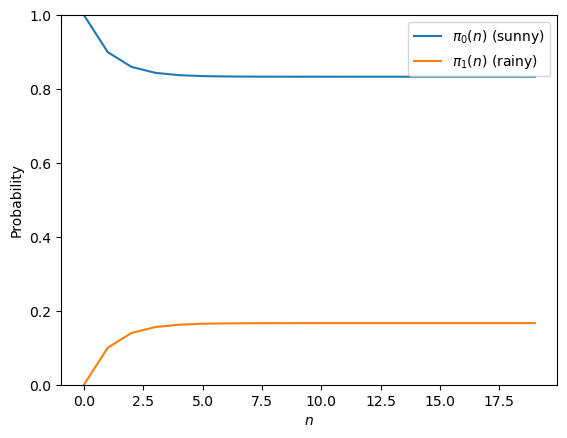

In [4]:
N = 20
pn = np.zeros([N,2]) # state occupancy probabilities after n steps
for n in range(0,N):
    pn[n,:] = dtmc(P, n, p0)

plt.plot(pn)
plt.ylim([0,1])
plt.xlabel("$n$")
plt.ylabel("Probability")
plt.legend(("$\\pi_0(n)$ (sunny)", "$\\pi_1(n)$ (rainy)"))
plt.show()

The plot above suggests that the stationary state occupancy probabilities are $(0.83, 1.67)$. The `dtmc()` function can be used to compute the stationary behavior of the DTMC, confirming our intuition:

In [5]:
print(dtmc(P))

[0.83333333 0.16666667]


$\pi_0$ (resp, $\pi_1$) can be interpreted as the average fraction of some time period (e.g., year) of sunny (resp, rainy) days. Therefore, under the model above, about 83% of a year is sunny, and 17% is rainy.

### Example: Machine repair 🛠️

([Source](https://math.libretexts.org/Bookshelves/Applied_Mathematics/Applied_Finite_Mathematics_(Sekhon_and_Bloom)/10%3A_Markov_Chains/10.02%3A_Applications_of_Markov_Chains/10.2.01%3A_Applications_of_Markov_Chains_(Exercises))) A machine can be in any of four states: (0) Idle; (1) Working; (2) Broken; (3) Repair. The machine is monitored every hour. The following matrix defines the transition probabilities between states, from one hour to the next one.

<center>
    <img src="machine-repair.svg" width="300px"/>
</center>

In [6]:
#              idle  work  brok  repa
P = np.array([[0.05, 0.93, 0.02,    0],   # idle
              [0.10, 0.86, 0.04,    0],   # work
              [   0,    0, 0.80, 0.20],   # brok
              [0.50, 0.10,    0, 0.40]]); # repa

# Let us give states a mnemonic name
IDLE = 0
WORK = 1
BROK = 2
REPA = 3

💡 **Q1**: What is the probability that the machine is working on a job three hours from now, if the machine is idle now?

In [7]:
p0 = np.zeros(4)
p0[IDLE] = 1
q1 = dtmc(P, 3, p0)
print(q1[WORK])

0.817033


💡 **Q2**: What is the probability that the machine is idle three hours from now if the machine is working on a job now?

In [8]:
p0 = np.zeros(4)
p0[WORK] = 1
q2 = dtmc(P, 3, p0)
print(q2[IDLE])

0.09181


💡 **Q3**: What is the probability that the machine is working on a job three hours from now if the machine is being repaired now?

In [9]:
p0 = np.zeros(4)
p0[REPA] = 1
q3 = dtmc(P, 3, p0)
print(q3[WORK])

0.7428100000000001


💡 **Q4**: What is the mean fraction of time the machine is not operational, i.e., either broken or being repaired?

In [10]:
q4 = dtmc(P)
print(q4[BROK] + q4[REPA])

0.19999999999999993


### Example (random walk) 🚶

Suppose that we place a coin into a $2 \times 2$ grid. At each step we move the coin to a neighboring cell with equal probability (the coin does not stay in the same cell).
The state space is $K=\{0, 1, 2, 3\}$ (indeed, there are four possible places and at each step the coin can be in exactly one of them). At the beginning the coin is placed on the top left cell (state 0).
The system can be represented by the following directed, weighted graph.

<center>
<img src="dtmc-2x2grid.svg" width="200px"/>
</center>

Let us first define the state transition matric $\mathbf{P}$ and the initial state occupancy probabiliti9es $\mathbf{\pi}_0$.

In [11]:
P = np.array([[0, 0.5, 0.5, 0],
              [0.5, 0, 0, 0.5],
              [0.5, 0, 0, 0.5],
              [0, 0.5, 0.5, 0]])
p0 = np.array([1, 0, 0, 0]) # start from state 0

💡 **Q:**  What is the state occupancy probabilities $\boldsymbol{\pi}(10)$ after 10 steps?

In [12]:
print(dtmc(P, 10, p0))

[0.5 0.  0.  0.5]


💡 **Q:**  Try with an odd number of steps $n$.

The steady-state probabilities $\boldsymbol{\pi}$ are:

In [13]:
print(dtmc(P))

[0.25 0.25 0.25 0.25]


### Example: mouse in a maze 🐭

A mouse is placed inside a maze of 9 rooms organized as a $3 \times 3$ matrix; the rooms are numbered from 0 (top left) to 8 (bottom right). Each room is connected to adjacent rooms (horizontally and vertically, not diagonally). At each step, the mouse moves from the current room to an adjacent one, with uniform probability. 

```
+---+---+---+
|   |   |   |
| 0   1   2 |
|   |   |   |
+- -+- -+- -+
|   |   |   |
| 3   4   5 |
|   |   |   |
+- -+- -+- -+
|   |   |   |
| 6   7   8 |
|   |   |   |
+---+---+---+
```

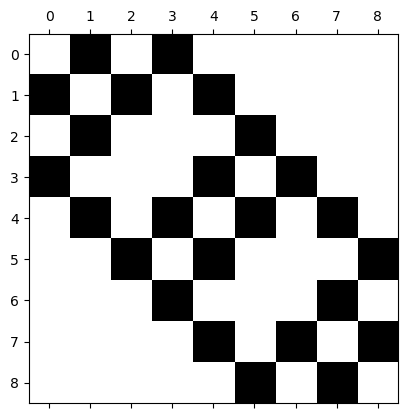

In [14]:
rat_maze = np.zeros([9,9])
rat_maze[0,[1, 3]   ] = 1/2
rat_maze[1,[0, 4, 2]] = 1/3
rat_maze[2,[1, 5]   ] = 1/2
rat_maze[3,[0, 4, 6]] = 1/3
rat_maze[4,[1, 3, 5, 7]] = 1/4
rat_maze[5,[2, 4, 8]] = 1/3
rat_maze[6,[3, 7]   ] = 1/2
rat_maze[7,[6, 4, 8]] = 1/3
rat_maze[8,[5, 7]   ] = 1/2
plt.spy(rat_maze);

💡 **Q:** Compute the stationary state occupancy probabilities.

[0.08333333 0.125      0.08333333 0.125      0.16666667 0.125
 0.08333333 0.125      0.08333333]


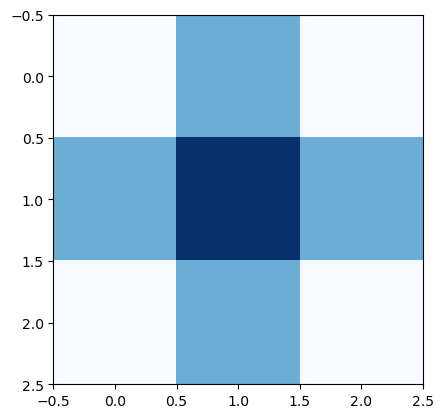

In [15]:
p = dtmc(rat_maze)
print(p)
assert np.allclose(p, [1/12, 1/8, 1/12, 1/8, 1/6, 1/8, 1/12, 1/8, 1/12]) # check the result
plt.imshow(p.reshape((3,3)), cmap='Blues');

### Transient and absorbing states

Given a DTMC, a state is _absorbing_ if it is not possible to leave that state once you enter it: if the system enters an absorbing state, it will stay there forever. A state that is not absorbing is said to be _transient_.

Analysis of transient and absorbing states involves the _fundamental matrix_ $\mathbf{N} = [n_{ij}]$ and the _absorption probability matrix_ $\mathbf{B} = [b_{ij}]$:

- $n_{ij}$ is the mean number of visits to transient state $j$ before absorption in any absorbing state, assuming that the system started in state $i$;
- $b_{ij}$ is the probability of entering absorbing state $j$, assuming that the system started in state $i$.

To compute $\mathbf{B}$ and $\mathbf{N}$ we need to permute the $k$ states such that the first $t$ are transient, and the remaining $r$ are absorbing ($k = t+r$). Then, the transition matrix $\mathbf{P}$ has the following shape:

$$
\mathbf{P} = \left( \begin{matrix}
\mathbf{Q} & \mathbf{R} \\
\mathbf{0} & \mathbf{I}_r
\end{matrix} \right)
$$

where $\mathbf{Q}$ has size $t \times t$, $\mathbf{R}$ has size $r \times t$, $\mathbf{0}$ is the zero matrix of size $r \times t$, and $\mathbf{I}_r$ is the identity matrix of sizd $r \times r$. Then 

$$
\begin{align}
\mathbf{N} &= (\mathbf{I}_r - \mathbf{Q})^{-1}\\
\mathbf{B} &= \mathbf{NR}
\end{align}
$$

The _mean time to absorption_ vector is defined as $\mathbf{t} = (t_0, \ldots, t_{k-1})$, where $t_i$ is the average number of steps before being absorbed in any absorbing state, starting from transient $i$. $\mathbf{t}$ can be computed as 

$$\mathbf{t} = \mathbf{N} \mathbf{1}^T$$ 

where matrix $\mathbf{N}$ is reshaped to size $k \times k$ by adding zero rows and columns, and $\mathbf{1}^T$ is a column vector of all ones.

In [16]:
def dtmcmtta(P, p0=None):
    """
    Analysis of an absorbing discrete-time Markov chain. This is a mostly
    automatic translation of the dtmcmtta() function from the Octave
    queueing package.

    Parameters
    ----------
    P : ndarray (k, k)
        Transition probability matrix.
    p0 : ndarray (k), optional
        Initial probability distribution.

    Returns
    -------
    t : ndarray(k) or scalar
        Mean time to absorption for each state.
        If p0 is not given, t[i] is the expected number of steps
        before being absorbed into any absorbing state, starting from
        state i.
        If p0 is given, t is the expected time to absorption (scalar)
        starting from the initial state occupancy probability p0.
    N : ndarray(k, k) or ndarray(k)
        Fundamental matrix.
        If p0 is not given, N[i,j] is the expected number of visits
        to transient state j before absorption, assuming that the system
        started in state i.
        If p0 is given, N[j] is the expected number of visits
        to transient state j before absorption, starting from
        the initial state occupancy probability p0.
    B : ndarray(k, k) or ndarray(k)
        Absorption probability matrix.
        If p0 is not given, B[i,j] is the probability of being absorbed in state j
        assuming that the system started in state i.
        If p0 is given, B[j] is the probability of being absorbed in state j given
        initial state occupancy probability p0.
    """
    P = np.asarray(P, dtype=float) # ensure P is of the proper type
    k = P.shape[0] # number of states
    # Identify transient and absorbing states
    tr = np.where(np.diag(P) < 1)[0]
    ab = np.where(np.diag(P) == 1)[0]
    num_tr = len(tr)
    if num_tr == k:
        raise ValueError("There are no absorbing states")
    N = np.zeros_like(P)
    B = np.zeros_like(P)
    t = np.zeros(k)
    # Fundamental matrix N = (I - Q)^(-1)
    Q = P[np.ix_(tr, tr)]
    tmpN = np.linalg.inv(np.eye(num_tr) - Q)
    N[np.ix_(tr, tr)] = tmpN # equivalent to N(tr,tr) in GNU Octave/MATLAB
    # Matrix of transitions from transient to absorbing states
    R = P[np.ix_(tr, ab)]
    # Mean time to absorption
    t[tr] = tmpN @ np.ones(num_tr)
    # Absorption probabilities
    tmp = tmpN @ R
    B[np.ix_(tr, ab)] = tmp
    # Set B(i,i)=1 for absorbing states
    B[ab, ab] = 1.0
    if p0 is not None:
        t = p0 @ t      # scalar
        N = p0 @ N      # row vector
        B = p0 @ B      # row vector
    return t, N, B

#P = np.array([[1, 0], [0.3, 0.2]])
#t,N,B = dtmcmtta(P)
#print(t)
#print(N)
#print(B)

### Example: rat maze with cheese 🐭 🧀

Let us consider again the rat maze example. At the beginning, the mouse is in room 0 and a piece of cheese in in room 8. The mouse moves randomly as in the previous example, but if it enters room 8, it stays there to eat the cheese. What is the expected number of random steps that are required to reach the cheese?

<center>
<img src="rat-maze.svg" width="300px"/>
</center>

To solve the problem, we define a new stochastic matrix `rat_maze_with_cheese` that is the same as `rat_maze`, with the only difference that we make state $8$ absorbing. To do so, we set all outgoing probabilities to zero, with the exception of $P_{88}$ that is set to one. Therefore, if the system enters state $8$ it will stay there forever.

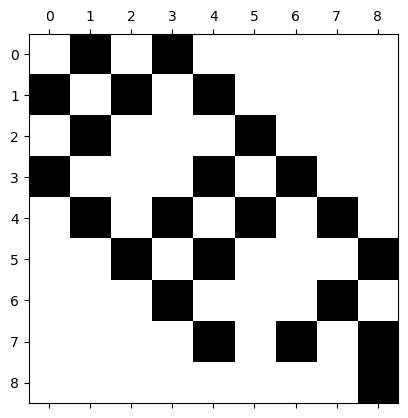

In [17]:
rat_maze_with_cheese = rat_maze.copy()
cheese = 8
rat_maze_with_cheese[cheese,:] = 0
rat_maze_with_cheese[cheese,cheese] = 1
plt.spy(rat_maze_with_cheese);

We use `dtmcmtta()` to compute the mean number of steps required to enter an absorbing state (there is just one, i.e., state $8$) starting from state $1$. To do so, we set the initial state occupancy probability to $[1, 0, 0, 0, 0, 0, 0, 0, 0]$. 

In [18]:
t, _, _ = dtmcmtta(rat_maze_with_cheese, [1, 0, 0, 0, 0, 0, 0, 0, 0])
print(t)

17.999999999999993


Therefore, a mouse that moves randomly inside the maze will need 18 steps to reach che cheese.

If we call `dtmcmtta()` with a single parameter, the result is an array $\mathbf{t} = \{t_0, \ldots, t_{K-1}\}$ where $t_i$ is the expected number of steps required to enter an absorbing state, assuming that the system starts in state $i$. We display the result as a $3 \times 3$ matrix, to have a bettere idea of the numbers. 

In [19]:
t, _, _ = dtmcmtta(rat_maze_with_cheese)
print(t.reshape((3,3)))

[[18. 17. 15.]
 [17. 15. 11.]
 [15. 11.  0.]]


Unsurprisingly, room 0 is the fartest to the goal and requires the largest number of steps to reach the cheese. 

The matrix is symmetric, which is expected. Interestingly, if we place the mouse on room $7$, that is adjacent to the goal, 11 steps are still required on average to reach the goal.

### Example: Snakes and Ladders 🐍🪜

![Snakes and Ladders By Auckland Museum, CC BY 4.0, https://commons.wikimedia.org/w/index.php?curid=84381903](snakes-and-ladders.jpg)

[Snakes and Ladders](https://en.wikipedia.org/wiki/Snakes_and_ladders) is a board game that originated in ancient India. The game is played by two players that are subject to the same rules, and whose progress is entirely determined by chance. Therefore, we can restrict ourselves to the case of a single player.

The board has $10 \times 10$ squares numbered from 1 to 100; an additional square 0 is the starting position of the player, and is never visited again. The board contains snakes (red arrows) and ladders (green arrows). At each turn, the player rolls a dice and advances a placeholder by as many squares as indicated by the dice (from one to six). If the landing position is the base of a ladder, then the placeholder is immediately moved to the top of the ladder. If the anding position is the tail of a snake, then the placeholder is immediately moved to the head of the snake. Using the figure below as a guide, if the placeholder visits the tail of an arrow, it is immediately moved to the tip of the arrow.

The placement of snakes and ladders on the board changes according to the vendor; in this exercise we assume the following (snakes are red arrows; ladders are green arrows).

![Snakes and ladders](snakes-and-ladders-board.svg)

For example, if the current position is 25 and the dice is three, then the placeholder should be moved to square 28 that is the bottom of a ladder, and therefore it goes directly to square 84. If the current position is 91 and the dice is two, then the placeholder should move to square 93 which is the head of a snake, so the final position is 73. 

To win the game it is necessary to land on square 100; it is not possible to move past 100, so if the player is on square, say, 97 and the dice is 6, the placeholder does not move.

The goal of this exercise is to compute the average number of moves that are required to win the game, i.e., reach square 100.

We model the game as a Markov chain; states are numbered from 0 to 100 (inclusive). States $i$ and $j$ are linked iff it is possible to go from $i$ to $j$ in a single move. 

If there were no snakes nor ladders, then the transition matrix $\mathbf{P}$ would be relatively easy to define: we can go from state $i$ to $i+d$, $d \in \{1, \ldots, 6\}$ with probability 1/6 each ($p_{i, i+d} = 1/6$). The only exceptions are $i \in \{95, 96, 97, 98, 99\}$, where there is nonzero probability to stay in $i$ if the dice lands us after square 100.

In [20]:
# First, define P as if there were no arrows
dice = 6
Psl = np.zeros([101,101]) # include cell 0
for i in range(0,101):
    for d in range(1,dice+1):
        if (i+d <= 100):
            Psl[i,i+d] = 1/dice
        else:
            Psl[i,i] += 1/dice

To take care of snakes and ladders, we define an array `SL` of pairs; each pair represents an arrow from the first to the second cell. 

In [21]:
SL = [[1, 38],
      [4, 14],
      [9, 31],
      [16, 6], 
      [21, 42],
      [28, 84],
      [36, 44],
      [47, 26],
      [49, 11], 
      [51, 67],
      [56, 53],
      [62, 19],
      [64, 60],
      [71, 91],
      [80, 100],
      [87, 24],
      [93, 73],
      [95, 75],
      [98, 78]]

Now the tricky part. For each snake (ladder) $(u, v)$ from state $u$ to state $v$, each transition entering $u$ must go to $v$ instead, since the player is "teleported" immediately to $v$. This means that:

- The probability $p_{s, u}$ to enter state $u$ from $s$ must be accumulated into $p_{s, v}$;
- It is not possible to enter state $u$: $p_{s, u} = 0$ for each $s$.

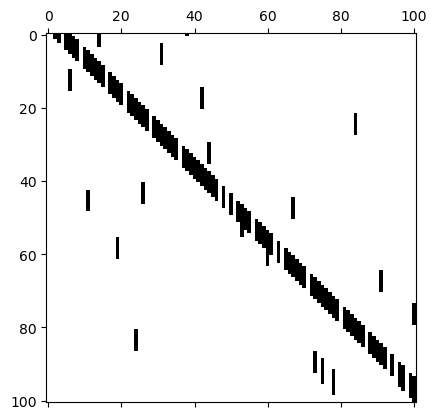

In [22]:
# For each snake/ladder (u,v), replace all transitions (s,u) with (s,v)
for sl in SL:
    u,v = sl # unpack 
    Psl[:,v] += Psl[:,u]
    Psl[:,u] = 0

# make state 100 absorbing
Psl[100,100] = 1

import matplotlib.pyplot as plt
plt.spy(Psl);

We use the function `dtmcmtta()` to compute the average number of steps that are required to win "snakes and ladders" starting from square zero.

In [34]:
# define the initial state occupancy probability: start in square 0
p0 = np.zeros(101)
p0[0] = 1
t, _, _ = dtmcmtta(Psl,p0)
print(t)

39.2251223082349


The result is the same as in the paper by Althoen, King, and Schilling cited in the references.

What is the probability of completing "snakes and ladders" in $\leq n$ steps? To answer this question we compute $\pi_{100}(0), \pi_{100}(1), \ldots$ using the formula for transient analysis of DTMC:

$$
\boldsymbol{\pi}(n) = \boldsymbol{\pi}(0) \mathbf{P}^n
$$

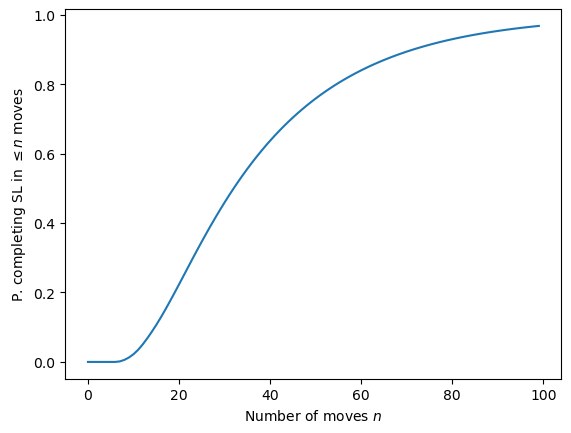

In [36]:
maxsteps = 100
pf = np.zeros(maxsteps)
pn = p0
for i in range(0,maxsteps):
    pf[i] = pn[100]
    pn = np.matmul(pn, Psl)

plt.plot(pf)
plt.xlabel("Number of moves $n$")
plt.ylabel("P. completing SL in $\\leq n$ moves")
plt.show()

## Continuous-Time Markov Chains (CTMC)

### Mathematical definition

A Continuous-Time Markov Chain (CTMC) is a set of stochastic variables $\{X(t), t \in \mathbb{R}^{\geq 0}\}$ over the state space $K=\{0, \ldots, k-1\}$. The definition of a CTMC relies on an _infinitesimal generator matrix_ $\mathbf{Q} = [ q_{ij} ]$. Let $p_{ij}(t, t+h)$ be the probability that the system is in state $j$ at time $t+h$, assuming that it was in state $i$ at time $t$. Then, 

$$
q_{ij} = \begin{cases}
\displaystyle \lim_{h \rightarrow 0} \frac{p_{ij}(t, t+h)}{h} & \mbox{if}\ i \neq j \\
\displaystyle \lim_{h \rightarrow 0} \frac{p_{ii}(t, t+h)-1}{h} & \mbox{if}\ i = j 
\end{cases}
$$

If $i \neq j$, $q_{ij}$ represents the _transition rate_ from state $i$ to state $j$; $q_{ii}$ is defined in such a way that the sum of row $i$ of $\mathbf{Q}$ is zero. The mean time spent in state $i$ before moving to another state is $\frac{1}{-q_{ii}}$.

Similarly to the discrete case, in CTMC we can compute the probabilities $\boldsymbol{\pi}(t) = (\pi_0(t), \ldots, \pi_{k-1}(t))$, where $\pi_i(t)$ is the probability that the system is in state $i$ at time $t$. Given the initial state occupancy probabilities $\boldsymbol{\pi}(0)$, $\boldsymbol{\pi}(t)$ can be computed as:

$$
\mathbf{\pi}(t) = \mathbf{\pi}(0) \exp({\mathbf{Q}t})
$$

The exponential of a square matrix $\mathbf{X}$ is defined as:

$$
\exp(\mathbf{X}) = \sum_{n=0}^{\infty} \frac{\mathbf{X}^n}{n!}
$$

The steady-state occupancy probability vector $\boldsymbol{\pi}$ is the solution of the set of linear equations:

$$
\left\{
\begin{align}
\boldsymbol{\pi Q} &= \mathbf{0}\\
\boldsymbol{\pi} \mathbf{1}^T &= \mathbf{1}
\end{align}
\right.
$$

where $\mathbf{1} = (1, \ldots, 1)$ is a row vector of length $k$ of ones, and $\mathbf{0}$ is the zero vector.

In [25]:

def ctmc(Q, *args):
    """
    ctmc(Q)
    ctmc(Q, t, p0)
    
    Continuous-Time Markov Chain (CTMC) analysis. This is a mostly automatic
    translation of the ctmc() function from the Octave queueing package.

    Parameters
    ----------
    Q : ndarray (K, K)
        Generator matrix.
    t : float
        Time for transient analysis.
        If omitted, steady-state analysis is performed.
    p0 : ndarray (K)
        Initial probability vector for transient analysis.

    Returns
    -------
    q : ndarray(K)
        if this function is called with one parameter: steady-state probability vector;
        otherwise, q(t) is the transient probability vector at time t.
    """
    Q = np.asarray(Q, dtype=float) # ensure Q is of the proper type
    eps = 10 * np.finfo(float).eps
    K = Q.shape[0]

    if Q.shape != (K, K) or K == 0:
        raise ValueError("Q must be a non-empty square matrix")

    if len(args) == 0:
        # ------------------------------------------------------------------
        # Steady-state analysis
        # ------------------------------------------------------------------
        # Find the index of nonzero columns of Q; one of these columns 
        # will be overwritten with the normalization condition.
        # This works as follows:
        # - np.abs(Q) > eps returns a k*k boolean matrix
        # - np.any(np.abs(Q) > eps, axis=0) returns a k boolean vector
        #   which is True on all columns for which there is a nonzero element.
        # - np.where(np.any(np.abs(Q) > eps, axis=0)) returns
        #   an array of indexes (actually, an array of pairs)
        #   corresponding to nonzero columns
        nonzero = np.where(np.any(np.abs(Q) > eps, axis=0))[0]
        if len(nonzero) == 0:
            raise ValueError("Q is the zero matrix")
        normcol = nonzero[0]
        # Work on a copy of Q
        A = Q.copy()
        # Force the probabilities of unvisited states to zero
        zero_cols = np.where(np.all(np.abs(A) < eps, axis=0))[0]
        for i in zero_cols:
            A[i, i] = 1.0
        # Replace the column chosen above with the normalization condition
        A[:, normcol] = 1.0
        b = np.zeros(K)
        b[normcol] = 1.0
        # Solve q A = b
        # Equivalent to Octave: q = b / Q
        q = np.linalg.solve(A.T, b)
        return q
    else:
        # ------------------------------------------------------------------
        # Transient analysis
        # ------------------------------------------------------------------
        t = args[0]
        p0 = args[1]
        q = p0 @ expm(Q * t)
        return q

# a small test
Q = np.array([[-1, 1, 0, 0], 
              [2, -3, 1, 0], 
              [0, 2, -3, 1], 
              [0, 0, 2, -2]])
q = ctmc(Q) # stationary analysis
print(q)
assert np.allclose(q, [8/15, 4/15, 2/15, 1/15])
q = ctmc(Q, 2.5, [0.1, 0.5, 0.4, 0.0]) # transient analysis
print(q)

[0.53333333 0.26666667 0.13333333 0.06666667]
[0.51881184 0.26682319 0.14059426 0.0737707 ]


### Example: reliability model of a multiprocessor systems 

A dual-processor system can operate correctly if at least one processor is operational. 
The Mean Time to Failure (MTTF) of each processor is $1/g = 5000h$. The Mean Time to Repair (MTTR) of a failed processor is $1/d = 4h$. If there are two active processors, and one of them fails, then the system can be reconfrigured to an operational state with one processor with probability $c = 0.9$; reconfiguration takes $1/b = 30s$ time. If reconfiguration is unsuccessfull (probability $1-c = 0.1$), then a reboot is required. The average time to reboot is $1/a = 10m$. 

The system is considered operational is:

- One or two processors are operational;
- The system is being reconfigured.

<center>
<img src="reliability.svg" width="400px"/>
</center>

In [26]:
# times in seconds
ss = 1
mm = 60*ss
hh = 60*mm
dd = 24*hh
yy = 365*dd
# parameters
a = 1/(10*mm)   # reboot takes 10 m
b = 1/(30*ss)   # reconfiguration takes 30 s
g = 1/(5000*hh) # processor MTTF is 5000 h
d = 1/(4*hh)    # processor MTTR is 4 h
c = 0.9         # probability of successful reconfiguration
# Provide meaningful names for states
ZERO, ONE, TWO, RC, RB = range(0,5)
# Initialize infinitesimal generator matrix
Qr = np.zeros([5,5])
Qr[ TWO,  RC] = 2*c*g;
Qr[ TWO,  RB] = 2*(1-c)*g
Qr[  RC,  ONE] = b
Qr[  RB,  ONE] = a
Qr[ ONE,  TWO] = d
Qr[ ONE, ZERO] = g
Qr[ZERO,  ONE] = d
# Set the diagonal of Qr such that the sum of each row is zero
# - np.sum(Qr, axis=1) is a column vector of row sums
# - Qr -= np.diag(...) subtracts from Qr a diagonal matrix
#   of the row sums above
Qr -= np.diag(np.sum(Qr, axis=1))

💡 **Q:**  What are the stationary state occupancy probabilities?

In [27]:
p = ctmc(Qr)
print(p)

[1.27794130e-06 1.59742663e-03 9.98391644e-01 2.99517493e-06
 6.65594430e-06]


From the stationary state occupancy probabilities we can derive many useful metrics. For example, the average time (in minutes) spent over a year in state RC, RB and ZERO is:

In [28]:
print(p[RC]*yy/mm) # minutes spent in state RC

1.5742639447457585


In [29]:
print(p[RB]*yy/mm) # minutes spent in state RB

3.49836432165724


In [30]:
print(p[ZERO]*yy/mm) # minutes spent in state ZERO

0.6716859497058889


### Expected Sojourn times

Given a CTMC, the _expected sojourn times_ $\mathbf{L}(t) = [ L_i(t) ]$ are the average total time spent in state $i$ in a given interval $[0,t]$. It can be computed using integration from the state occupancy probabilities:

$$
\mathbf{L}(t) = \int_{0}^t \boldsymbol{\pi}(u) du
$$

$\mathbf{L} = [ L_i ]$ is the average time spent in transient state $i$ before absorption, assuming initial state occupancy probabilities $\boldsymbol{\pi}(0)$. It can be computed as the solution of the following linear system:

$$
\mathbf{L} \mathbf{Q}_\tau = - \boldsymbol{\pi}(0)
$$

where $\mathbf{Q}_\tau$ is the restriction of matrix $\mathbf{Q}$ to the set $\tau$ of transient states.

The function `ctmcexps()` can be used to compute $\mathbf{L}(t)$ and $\mathbf{L}$.

In [31]:
def ctmcexps(Q, *args):
    """
    ctmcexps(Q, p0)
    ctmcexps(Q, t, p0)
    
    Compute the expected sojourn times of a CTMC. This is a mostly
    automatic translation of the ctmcexps() function from the
    Octave queueing package.

    Parameters
    ----------
    Q : ndarray (k, k)
        CTMC infinitesimal generator.
    args :
        Either:
            (p0,)   -> (ndarray k) initial state occupancy probabilities; p0[i]
                       is the initial probability that the system is in state i.
            (t, p0) -> (scalar, ndarray k) compute expected sojourn times in [0, t] given
                       the initial state occupancy probabilities p0.

    Returns
    -------
    L : ndarray(k)
        If this function is called with three parameters, L[i] is the
        expected time spent in state i during the interval [0,t]. If this
        function is called with two parameters, L[i] is the expected time spent in transient
        state i until absorption; it state i is absorbing, L[i] is zero.
    """

    Q = np.asarray(Q, dtype=float)
    k = Q.shape[0]

    if len(args) == 1:
        p0 = np.asarray(args[0], dtype=float)
    else:
        t = args[0]
        p0 = np.asarray(args[1], dtype=float)

    p0 = p0.reshape(1, -1)  # row vector

    if len(args) == 2:
        # ------------------------------------------------------------------
        # Non-absorbing case: ctmcexps(Q, t, p0)
        # ------------------------------------------------------------------
        if t < 0:
            raise ValueError("t must be >= 0")
        # F(x) = p0 * expm(Q*x)
        def F(x):
            return p0 @ expm(Q * x)
        # Integral from 0 to t
        L, _ = quad_vec(F, 0.0, t)
        return np.asarray(L).ravel()
    else:
        # ------------------------------------------------------------------
        # Absorbing case: ctmcexps(Q, p0)
        # ------------------------------------------------------------------  
        # Non-absorbing states (rows having at least one nonzero element)
        tr = np.where(np.any(np.abs(Q) > EPSILON, axis=1))[0]
        if len(tr) == k:
            raise ValueError("There are no absorbing states")
        QN = Q[np.ix_(tr, tr)]
        pN = p0[0, tr]
        LN = -pN @ np.linalg.inv(QN)
        L = np.zeros(k)
        L[tr] = LN
        return L

The _Mean Time to Absorption_ (MTTA) $L$ is the sum of all sojourn times until absorption:

$$
L = \sum_{i=0}^{k-1} L_i
$$

In [32]:
def ctmcmtta(Q, p):
    L = ctmcexps(Q, p)
    return np.sum(L)

Q = np.array([[  0, 0.1,   0,   0],
              [0.9,   0, 0.1,   0],
              [  0, 0.9,   0, 0.1],
              [  0,   0,   0,   0]])
Q -= np.diag(np.sum(Q, axis=1))
print(Q)
ctmcmtta(Q, [0, 0, 1, 0])

[[-0.1  0.1  0.   0. ]
 [ 0.9 -1.   0.1  0. ]
 [ 0.   0.9 -1.   0.1]
 [ 0.   0.   0.   0. ]]


909.9999999999995

We now see how the MTTA can be useful in many modeling applications.

### Reliability model of a multiprocessor system (cont.)

Consider again the reliability model of a multiprocessor system above. The Mean Time Between Failures (MTBF) is the average duration of continuous operation. We assume that the system starts in state 2, and we consider the system operational if it is in any state in $\{0, 1, \mathit{RC}\}$. 

To compute the MTBF, we make states 0 and RB absorbing by setting all outgoing transition rates to zero. 
The MTBF is then the mean time to absorption of the modified CTMC.

<center>
    <img src="reliability_absorb.svg" width="400px"/>
</center>

💡 **Q:**  What is the MTBF in years?

In [33]:
Qr[ZERO,:] = 0   # remove all outgoing transitions...
Qr[RB,:] = 0     # ...from states ZERO and RB
p0 = np.zeros(5) # define initial state occupancy probabilities...
p0[TWO] = 1      # ...the system starts in state TWO
MTBF = ctmcmtta(Qr, p0)
print(MTBF/yy) # MTBF in years

2.837581886007826


# References

- Moreno Marzolla, [The Octave Queueing package](https://github.com/mmarzolla/queueing) and [documentation](https://www.moreno.marzolla.name/software/queueing/queueing.pdf).
- Moreno Marzolla, [A Software Package for Queueing Networks and Markov Chains analysis](https://arxiv.org/abs/2209.04220), arXiv Preprint 2209.04220, Sep 2022. 
- Althoen, S. C., et al. _How Long Is a Game of Snakes and Ladders?_ The Mathematical Gazette, vol. 77, no. 478, 1993, pp. 71–76. JSTOR, https://doi.org/10.2307/3619261. Accessed 13 Nov. 2026.
- Gunter Bolch, Stefan Greiner, Hermann de Meer, Kishor S. Trivedi, _Queueing Networks and Markov Chains: Modeling and Performance Evaluation With Computer Science Applications_,
John Wiley & Sons, 2006, ISBN:9780471565253, DOI:10.1002/0471791571.